# Per-chain visualisations at $d = 100$, depth $1000$

This notebook produces the two main-paper d=100 visualisation figures:

- `pi_Z_tsne_d100.pdf` &nbsp; (Figure 3) &nbsp; main-paper t-SNE figure.
- `pi_Z_pca_d100.pdf` &nbsp; (Figure 12) &nbsp; PCA companion in the appendix.

The depth is chosen as $i = 1000$ to give a comfortable margin over the
near-critical mixing time visible in Figure 2 for $\lambda \in \{0.99, 0.995\}$.

Approximate runtime: about 30--40 minutes on a single CPU core (heaviest of the
four notebooks; $5$ chains $\times 3 \lambda$ values $\times 1000$ Cholesky
factorisations of a $1000 \times 1000$ matrix).

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms
from sklearn.manifold import TSNE
from chain import r_c_of_d, simulate_Z_chain

FIGS = Path("figs")
FIGS.mkdir(exist_ok=True)

PERPLEXITY = 30
PANEL_W = 2.0
PANEL_H = 1.55
PANEL_H_HIST = 1.30


def pca2(X):
    Xc = X - X.mean(axis=0, keepdims=True)
    if np.std(Xc) < 1e-12:
        Xc = Xc + 1e-12 * np.random.default_rng(0).standard_normal(size=Xc.shape)
    U, s, Vt = np.linalg.svd(Xc, full_matrices=False)
    scores = U[:, :2] * s[:2]
    for k in range(2):
        idx = int(np.argmax(np.abs(Vt[k])))
        if Vt[k, idx] < 0:
            scores[:, k] = -scores[:, k]
    return scores


def simulate_per_chain(d, n, lams, depth, n_chains, seeds, jitter=1e-8):
    # Return array of shape (n_lams, n_chains, n, d): final-depth Z snapshot.
    out = np.empty((len(lams), n_chains, n, d))
    rc = r_c_of_d(d)
    for li, lam in enumerate(lams):
        r = lam * rc
        rng = np.random.default_rng(seeds[lam])
        for c in range(n_chains):
            snaps = simulate_Z_chain(r=r, n=n, d=d, n_steps=depth, rng=rng,
                                     save_depths=(depth,), jitter=jitter)
            out[li, c] = snaps[depth]
    return out


def grid_pca(snap, lams, d, depth, out_path, n_chains, main_path=None, n_main_rows=None):
    colors = plt.get_cmap("tab10").colors[:n_chains]
    fig, axes = plt.subplots(len(lams), n_chains,
                              figsize=(PANEL_W * n_chains, PANEL_H * len(lams)))
    for li, lam in enumerate(lams):
        sc = np.stack([pca2(snap[li, c]) for c in range(n_chains)], axis=0)
        lim = max(float(np.quantile(np.abs(sc), 0.99)), 1e-6)
        for c in range(n_chains):
            ax = axes[li, c]
            ax.scatter(sc[c, :, 0], sc[c, :, 1], s=4, color=colors[c],
                       alpha=0.55, linewidths=0)
            ax.axhline(0, color="k", lw=0.3, alpha=0.3)
            ax.axvline(0, color="k", lw=0.3, alpha=0.3)
            ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
            ax.set_aspect("equal", adjustable="box")
            ax.set_xticks([]); ax.set_yticks([])
            if li == 0:
                ax.set_title(f"chain {c}", fontsize=8, color=colors[c])
            if c == 0:
                ax.set_ylabel(fr"$\lambda = {lam}$", fontsize=8)
    fig.suptitle(fr"$d = {d}$, depth $i = {depth}$: PC1--PC2 of $\bar Z_{{i,t}}$, per chain.",
                 fontsize=9)
    fig.tight_layout()
    cropped_bbox_inches = None
    if main_path is not None and n_main_rows is not None and n_main_rows < len(lams):
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        tight_in = fig.get_tightbbox(renderer)
        inv = fig.dpi_scale_trans.inverted()
        last_keep_in = mtransforms.Bbox.union(
            [axes[n_main_rows - 1, c].get_tightbbox(renderer).transformed(inv)
             for c in range(n_chains)]
        )
        y_cut_in = last_keep_in.y0 - 0.04
        cropped_bbox_inches = mtransforms.Bbox.from_extents(
            tight_in.x0, y_cut_in, tight_in.x1, tight_in.y1
        )
    fig.savefig(out_path, bbox_inches="tight")
    print(f"wrote {out_path}")
    if cropped_bbox_inches is not None:
        fig.savefig(main_path, bbox_inches=cropped_bbox_inches)
        print(f"wrote {main_path}")
    plt.show()


def grid_tsne(snap, lams, d, depth, out_path, n_chains):
    colors = plt.get_cmap("tab10").colors[:n_chains]
    fig, axes = plt.subplots(len(lams), n_chains,
                              figsize=(PANEL_W * n_chains, PANEL_H * len(lams)))
    for li, lam in enumerate(lams):
        for c in range(n_chains):
            X = snap[li, c]
            if np.std(X) < 1e-12:
                X = X + 1e-12 * np.random.default_rng(c).standard_normal(size=X.shape)
            emb = TSNE(n_components=2, perplexity=PERPLEXITY, init="pca",
                       random_state=0).fit_transform(X)
            ax = axes[li, c]
            ax.scatter(emb[:, 0], emb[:, 1], s=4, color=colors[c], alpha=0.55, linewidths=0)
            ax.set_xticks([]); ax.set_yticks([])
            ax.set_aspect("equal", adjustable="datalim")
            if li == 0:
                ax.set_title(f"chain {c}", fontsize=8, color=colors[c])
            if c == 0:
                ax.set_ylabel(fr"$\lambda = {lam}$", fontsize=8)
    fig.suptitle(fr"$d = {d}$, depth $i = {depth}$: t-SNE (perplexity {PERPLEXITY}) of $\bar Z_{{i,t}}$.",
                 fontsize=9)
    fig.tight_layout()
    fig.savefig(out_path, bbox_inches="tight")
    plt.show()
    print(f"wrote {out_path}")


def grid_hist_d1(snap, lams, depth, out_path, n_chains):
    colors = plt.get_cmap("tab10").colors[:n_chains]
    fig, axes = plt.subplots(len(lams), n_chains,
                              figsize=(PANEL_W * n_chains, PANEL_H_HIST * len(lams)))
    n_bins = 80
    for li, lam in enumerate(lams):
        all_vals = snap[li].ravel()
        lo = float(np.quantile(all_vals, 0.001))
        hi = float(np.quantile(all_vals, 0.999))
        lim = max(abs(lo), abs(hi), 1e-6)
        bins = np.linspace(-lim, lim, n_bins + 1)
        for c in range(n_chains):
            ax = axes[li, c]
            ax.hist(snap[li, c, :, 0], bins=bins, density=True,
                    color=colors[c], edgecolor=colors[c], linewidth=0.4, alpha=0.75)
            xs = np.linspace(-lim, lim, 400)
            ax.plot(xs, np.exp(-0.5 * xs**2) / np.sqrt(2 * np.pi),
                    "k--", lw=0.7, alpha=0.6)
            ax.set_xticks([]); ax.set_yticks([])
            if li == 0:
                ax.set_title(f"chain {c}", fontsize=8, color=colors[c])
            if c == 0:
                ax.set_ylabel(fr"$\lambda = {lam}$", fontsize=8)
    fig.suptitle(fr"$d = 1$, depth $i = {depth}$: histogram of $\bar Z_{{i,t}}$, per chain. Dashed: $\mathcal{{N}}(0,1)$.",
                 fontsize=9)
    fig.tight_layout()
    fig.savefig(out_path, bbox_inches="tight")
    plt.show()
    print(f"wrote {out_path}")

## Simulate $d = 100$ chains

$n = 1000$ points, depth $1000$, five i.i.d.\ chains, three $\lambda$ values
$\{0.90, 0.99, 0.995\}$ in the visible-structure strip.

In [2]:
LAMS_D100 = (0.90, 0.99, 0.995)
DEPTH_D100 = 1000
N = 1000
N_CHAINS = 5
SEEDS_D100 = {0.90: 1234, 0.99: 2024, 0.995: 2025}
snap100 = simulate_per_chain(d=100, n=N, lams=LAMS_D100, depth=DEPTH_D100,
                             n_chains=N_CHAINS, seeds=SEEDS_D100)
print("snap100 shape:", snap100.shape)

snap100 shape: (3, 5, 1000, 100)


## Figure 3 — `pi_Z_tsne_d100.pdf`

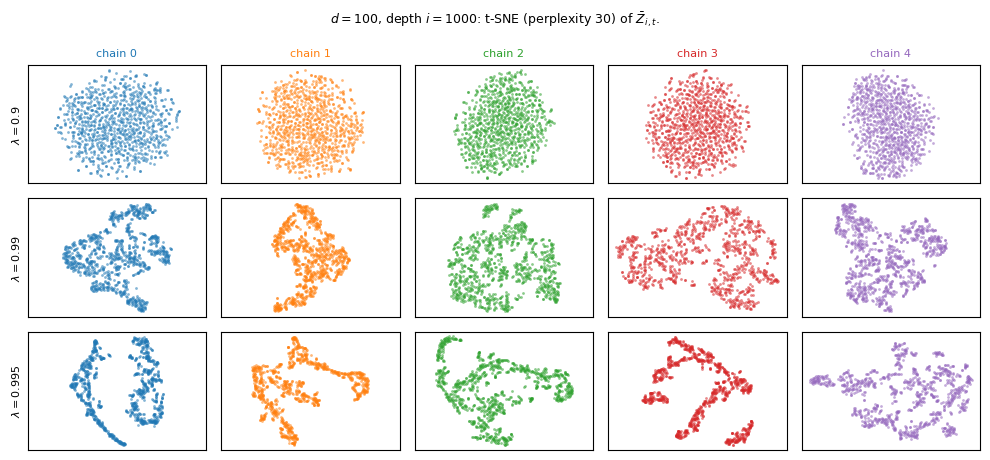

wrote figs/pi_Z_tsne_d100.pdf


In [3]:
grid_tsne(snap100, LAMS_D100, d=100, depth=DEPTH_D100,
          out_path=FIGS / "pi_Z_tsne_d100.pdf", n_chains=N_CHAINS)

## Figure 12 — `pi_Z_pca_d100.pdf`

wrote figs/pi_Z_pca_d100.pdf


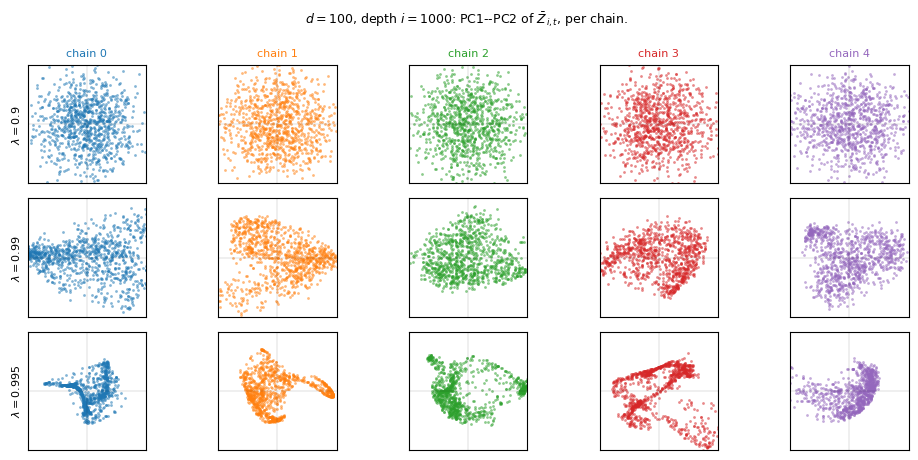

In [4]:
grid_pca(snap100, LAMS_D100, d=100, depth=DEPTH_D100,
         out_path=FIGS / "pi_Z_pca_d100.pdf", n_chains=N_CHAINS)